# NN_L4_receptive_field

**Receptive field of stacked 3 x 3 convolutions, with and without 2 x 2 pooling, from the recursion r_l = r_(l-1) + (k_l - 1) prod s_i.**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_receptive_field/NN_L4_receptive_field.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Receptive field $r_l=r_{l-1}+(k_l-1)\prod_{i<l}s_i$, $r_0=1$.

twelve 3x3 layers = 25   [rf.plain_12]
eight 3x3 layers with pooling = 68   [rf.pooled_8conv]


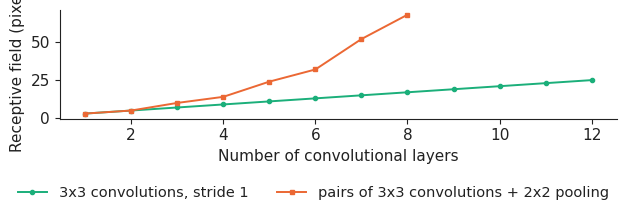

In [3]:
def rf(layers):
    r, j, out = 1, 1, []
    for k, s in layers:
        r += (k - 1) * j; j *= s; out.append(r)
    return out
plain = rf([(3, 1)] * 12)
pooled = [v for i, v in enumerate(rf([(3, 1), (3, 1), (2, 2)] * 4)) if i % 3 != 2][:8]
show('rf.plain_12', 'twelve 3x3 layers', plain[11]); show('rf.pooled_8conv', 'eight 3x3 layers with pooling', pooled[7])
fig, ax = plt.subplots(figsize=(6.4, 2.2))
ax.plot(range(1, 13), plain, marker='o', ms=3, color=PAL['benchmark'], label='3x3 convolutions, stride 1')
ax.plot(range(1, 9), pooled, marker='s', ms=3, color=PAL['model'], label='pairs of 3x3 convolutions + 2x2 pooling')
ax.set_xlabel('Number of convolutional layers'); ax.set_ylabel('Receptive field (pixels)')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.15, 1, 1))
fig.savefig('receptive_field.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()